# Perbandingan N-gram TF-IDF + Logistic Regression (SATUSEHAT) — versi revisi
Perbaikan sesuai 5 poin revisi:
1. Pemilihan model berdasarkan CV, tidak menobatkan satu model "terbaik" dari akurasi uji
2. Audit manual kesalahan prediksi (ekspor + rekap)
3. Variasi `min_df` dan perbandingan pada ulasan yang sama
4. `TfidfVectorizer` di dalam `Pipeline` (fit ulang tiap fold)
5. Replikasi: seed tercatat + ekspor data hasil preprocessing

**Tambahan (v2):** sel baru untuk Tabel 2 (karakteristik dataset), Tabel 3 (cakupan fitur, termasuk kolom latih), interval Wilson dan Wald berikut ambang Bonferroni, verifikasi sampel 20 ulasan, serta Gambar 2 dan Gambar 3 sebagai berkas gambar.

**Tambahan (v3):** Langkah 0 sekarang mencakup cleaning di Python (menggantikan Altair AI Studio) dan sampling acak berseed 2.000 positif + 2.000 negatif, dengan urutan *cleaning dulu, baru sampling* sehingga jumlah per kelas pasti seimbang. Semua keluaran lama (angka, tabel) dikosongkan; jalankan ulang dari atas.

In [3]:
import sys, os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn, scipy

from scipy.stats import binomtest
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report, accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, roc_curve, confusion_matrix
)

SEED = 42   # satu seed untuk SEMUA proses acak (sampling, split, model)
plt.rcParams['figure.dpi'] = 150
sns.set_theme(style="whitegrid")

# Catat versi untuk dicantumkan di artikel (poin 5)
print("Python      :", sys.version.split()[0])
print("scikit-learn:", sklearn.__version__)
print("pandas      :", pd.__version__)
print("numpy       :", np.__version__)
print("scipy       :", scipy.__version__)
print("SEED        :", SEED)

Python      : 3.13.0
scikit-learn: 1.7.2
pandas      : 2.3.3
numpy       : 2.3.4
scipy       : 1.16.3
SEED        : 42


## Langkah 0 — Cleaning dan sampling dengan seed tercatat
Membangun dataset dari data mentah IGAR v3 (`Rating_labeled.csv`) dengan urutan: ambil subset SATUSEHAT, buang skor 3 (Neutral) dan ulasan tanpa teks, **cleaning** (hanya huruf dan spasi yang dipertahankan), buang ulasan kosong dan duplikat, lalu **sampling acak per kelas** (*stratified random sampling*, alokasi sama: 2.000 positif + 2.000 negatif, `random_state = SEED`).

Hasilnya disimpan sebagai `SATUSEHAT_clean_balanced.csv`, yang dibaca oleh Langkah 1. Jalankan sekali; setelah berkas itu ada, `RUN_SAMPLING` boleh diubah ke `False`.
**Dataset berubah dibanding versi sebelumnya, sehingga semua angka di artikel ikut berubah.**


In [4]:
RUN_SAMPLING = True                    # True = bangun ulang dataset dari data mentah; False = pakai SATUSEHAT_clean_balanced.csv yang sudah ada
RAW_FILE = 'Rating_labeled.csv'        # data mentah IGAR v3 (pemisah koma, kolom pertama = indeks)
N_PER_CLASS = 2000

def bersihkan(teks):
    """Cleaning dasar: hanya huruf A-Z/a-z dan spasi yang dipertahankan."""
    teks = re.sub(r'[^A-Za-z\s]', ' ', str(teks))   # hapus tanda baca, angka, emoji
    return re.sub(r'\s+', ' ', teks).strip()         # rapikan spasi

if RUN_SAMPLING:
    raw = pd.read_csv(RAW_FILE, index_col=0)
    print(f"Seluruh IGAR v3                      : {len(raw):,}")
    raw = raw[raw['app'].str.lower() == 'satusehat']
    print(f"Subset SATUSEHAT                     : {len(raw):,}")
    raw = raw[raw['labelScoreBase'].isin(['Positive', 'Negative'])]      # skor 3 (Neutral) dibuang
    print(f"Setelah skor 3 dibuang               : {len(raw):,}")
    raw = raw.dropna(subset=['content']).copy()
    print(f"Setelah ulasan tanpa teks dibuang    : {len(raw):,}")

    raw['content_asli'] = raw['content']
    raw['content'] = raw['content'].map(bersihkan)
    raw = raw[raw['content'] != '']                                      # ulasan kosong setelah cleaning
    print(f"Setelah ulasan kosong dibuang        : {len(raw):,}")
    raw = raw[~raw['content'].str.lower().duplicated()]                  # duplikat (tanpa membedakan huruf besar/kecil)
    print(f"Setelah duplikat dibuang             : {len(raw):,}")
    print(raw['labelScoreBase'].value_counts().to_string())

    pos = raw[raw['labelScoreBase'] == 'Positive'].sample(n=N_PER_CLASS, random_state=SEED)
    neg = raw[raw['labelScoreBase'] == 'Negative'].sample(n=N_PER_CLASS, random_state=SEED)
    sampled = pd.concat([pos, neg]).sample(frac=1, random_state=SEED).reset_index(drop=True)
    assert sampled['labelScoreBase'].value_counts().eq(N_PER_CLASS).all()

    sampled = sampled[['app', 'content', 'content_asli', 'score', 'at', 'labelScoreBase']]
    sampled.to_csv('SATUSEHAT_clean_balanced.csv', sep=';', index=False)
    print("\nSampel tersimpan (SATUSEHAT_clean_balanced.csv):", sampled.shape)


Seluruh IGAR v3                      : 617,722
Subset SATUSEHAT                     : 190,696
Setelah skor 3 dibuang               : 177,625
Setelah ulasan tanpa teks dibuang    : 177,622
Setelah ulasan kosong dibuang        : 175,058
Setelah duplikat dibuang             : 116,076
labelScoreBase
Negative    73674
Positive    42402

Sampel tersimpan (SATUSEHAT_clean_balanced.csv): (4000, 6)


## Langkah 1 — Muat data dan bagi data

In [5]:
df = pd.read_csv('SATUSEHAT_clean_balanced.csv', sep=';')
df['label'] = df['labelScoreBase'].map({'Positive': 1, 'Negative': 0})
df['content'] = df['content'].astype(str)

X = df['content']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

print("Total Data      :", len(df))
print("Data Latih (80%):", len(X_train))
print("Data Uji (20%)  :", len(X_test))

# Ekspor data hasil preprocessing + penanda split (poin 5) -> unggah ke GitHub/Zenodo
export = df.copy()
export['split'] = 'train'
export.loc[X_test.index, 'split'] = 'test'
export.to_csv('SATUSEHAT_preprocessed_split.csv', sep=';', index=True, index_label='row_id')
print("Tersimpan: SATUSEHAT_preprocessed_split.csv")

Total Data      : 4000
Data Latih (80%): 3200
Data Uji (20%)  : 800
Tersimpan: SATUSEHAT_preprocessed_split.csv


## Tabel 2 — Karakteristik dataset
Dihitung langsung dari data hasil praproses, agar angka pada Tabel 2 artikel dapat direproduksi. Pencarian istilah memakai pola huruf tidak peka kapital; kolom "ulasan" adalah jumlah ulasan unik yang memuat istilah (satu ulasan dihitung sekali).

In [6]:
# Nilai kosong diperiksa pada data mentah (df['content'] di atas sudah diubah ke str)
df_raw = pd.read_csv('SATUSEHAT_clean_balanced.csv', sep=';')
waktu = pd.to_datetime(df_raw['at'])
n_kata = df['content'].str.split().str.len()

print(f"Jumlah ulasan             : {len(df_raw)}")
print(f"Positif / negatif         : {int((df['label']==1).sum())} / {int((df['label']==0).sum())}")
print(f"Nilai kosong / duplikat   : {int(df_raw['content'].isna().sum())} / {int(df_raw['content'].duplicated().sum())}")
print(f"Periode ulasan            : {waktu.min():%d-%m-%Y} s.d. {waktu.max():%d-%m-%Y}")
print()
print("Panjang ulasan (jumlah kata)  rata-rata | median | maks")
for nama, m in [("Semua", slice(None)), ("Negatif", df['label']==0), ("Positif", df['label']==1)]:
    x = n_kata[m]
    print(f"  {nama:8s}: {x.mean():6.2f} | {x.median():5.1f} | {int(x.max())}")
print()
istilah = {
    'PeduliLindungi / Peduli Lindungi': r'peduli\s?lindungi',
    'SATUSEHAT / Satu Sehat'          : r'satu\s?sehat',
    'vaksin'                          : r'vaksin',
    'sertifikat'                      : r'sertifikat',
    'covid'                           : r'covid',
}
print("Ulasan yang memuat istilah:")
for k, pola in istilah.items():
    print(f"  {k:34s}: {int(df['content'].str.contains(pola, case=False, regex=True).sum())}")


Jumlah ulasan             : 4000
Positif / negatif         : 2000 / 2000
Nilai kosong / duplikat   : 0 / 0
Periode ulasan            : 31-03-2020 s.d. 14-10-2021

Panjang ulasan (jumlah kata)  rata-rata | median | maks
  Semua   :  13.17 |   9.0 | 101
  Negatif :  16.41 |  12.0 | 94
  Positif :   9.93 |   6.0 | 101

Ulasan yang memuat istilah:
  PeduliLindungi / Peduli Lindungi  : 175
  SATUSEHAT / Satu Sehat            : 0
  vaksin                            : 949
  sertifikat                        : 697
  covid                             : 136


## Langkah 2 — Eksperimen utama (min_df = 3, C disetel lewat CV)
`TfidfVectorizer` ada **di dalam Pipeline**, jadi dihitung ulang di setiap fold (poin 4).

In [7]:
experiments = [
    ("Unigram", (1, 1)),
    ("Bigram", (2, 2)),
    ("Unigram + Bigram", (1, 2)),
]
C_GRID = [0.01, 0.1, 1.0, 10.0]
MIN_DF_MAIN = 3

def make_pipeline(ngram, min_df):
    return Pipeline([
        ('tfidf', TfidfVectorizer(ngram_range=ngram, min_df=min_df)),
        ('classifier', LogisticRegression(max_iter=1000, random_state=SEED)),
    ])

def fit_config(ngram, min_df):
    gs = GridSearchCV(
        make_pipeline(ngram, min_df),
        param_grid={'classifier__C': C_GRID},
        cv=5, scoring='accuracy', n_jobs=-1,
    )
    gs.fit(X_train, y_train)
    return gs

results_main, models_dict = [], {}
for name, ngram in experiments:
    gs = fit_config(ngram, MIN_DF_MAIN)
    best = gs.best_estimator_
    y_pred = best.predict(X_test)
    y_prob = best.predict_proba(X_test)[:, 1]
    models_dict[name] = {'best_model': best, 'grid': gs, 'y_pred': y_pred, 'y_prob': y_prob}

    vec = best.named_steps['tfidf']
    results_main.append({
        'Skema N-Gram': name,
        'Best C': gs.best_params_['classifier__C'],
        'Total Fitur': len(vec.get_feature_names_out()),
        'Akurasi CV': gs.best_score_,
        'Akurasi Test': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_prob),
        'Ulasan uji tanpa fitur': int((vec.transform(X_test).getnnz(axis=1) == 0).sum()),
    })

df_results = pd.DataFrame(results_main)
print("=== HASIL N-GRAM (min_df = 3) ===")
print(df_results.round(4).to_string(index=False))

=== HASIL N-GRAM (min_df = 3) ===
    Skema N-Gram  Best C  Total Fitur  Akurasi CV  Akurasi Test  Precision  Recall  F1-Score  ROC-AUC  Ulasan uji tanpa fitur
         Unigram     1.0         1423      0.8247        0.8300     0.8587   0.790    0.8229   0.9098                      27
          Bigram     1.0         1984      0.7684        0.7812     0.7494   0.845    0.7944   0.8528                     206
Unigram + Bigram     1.0         3407      0.8322        0.8362     0.8705   0.790    0.8283   0.9121                      27


## Tabel 3 — Cakupan fitur per konfigurasi
Jumlah fitur TF-IDF (min_df = 3, dilatih hanya pada data latih) dan jumlah ulasan yang tidak memiliki satu pun fitur (vektor nol), baik pada data latih maupun data uji.

In [8]:
rows = []
for name, info in models_dict.items():
    vec = info['best_model'].named_steps['tfidf']
    nol_latih = int((vec.transform(X_train).getnnz(axis=1) == 0).sum())
    nol_uji   = int((vec.transform(X_test).getnnz(axis=1) == 0).sum())
    rows.append({
        'Konfigurasi'                        : name,
        'ngram_range'                        : vec.ngram_range,
        'Jumlah fitur'                       : len(vec.get_feature_names_out()),
        f'Latih tanpa fitur (dari {len(X_train)})': nol_latih,
        f'Uji tanpa fitur (dari {len(X_test)})'   : nol_uji,
        'Uji tanpa fitur (%)'                : round(nol_uji / len(X_test) * 100, 1),
    })
display(pd.DataFrame(rows).set_index('Konfigurasi'))


,ngram_range,Jumlah fitur,Latih tanpa fitur (dari 3200),Uji tanpa fitur (dari 800),Uji tanpa fitur (%)
Konfigurasi,,,,,
Unigram,"(1, 1)",1423,96,27,3.4
Bigram,"(2, 2)",1984,632,206,25.8
Unigram + Bigram,"(1, 2)",3407,96,27,3.4


## Poin 1 — Kriteria pemilihan model
Model acuan dipilih berdasarkan **akurasi CV**, bukan akurasi uji. Data uji hanya untuk pelaporan akhir.

In [9]:
idx = df_results['Akurasi CV'].idxmax()
selected_name = df_results.loc[idx, 'Skema N-Gram']
print(f"Konfigurasi dengan akurasi CV tertinggi: {selected_name} "
      f"({df_results.loc[idx, 'Akurasi CV']*100:.2f}%)")
print(df_results[['Skema N-Gram', 'Akurasi CV', 'Akurasi Test']].round(4).to_string(index=False))
print()
print("Catatan: jika selisih antar-konfigurasi tidak signifikan (lihat McNemar di bawah),")
print("laporkan ketiganya setara dan JANGAN menyebut satu pun 'terbaik' di artikel.")

Konfigurasi dengan akurasi CV tertinggi: Unigram + Bigram (83.22%)
    Skema N-Gram  Akurasi CV  Akurasi Test
         Unigram      0.8247        0.8300
          Bigram      0.7684        0.7812
Unigram + Bigram      0.8322        0.8362

Catatan: jika selisih antar-konfigurasi tidak signifikan (lihat McNemar di bawah),
laporkan ketiganya setara dan JANGAN menyebut satu pun 'terbaik' di artikel.


## Tabel 4 — Akurasi CV per nilai C

In [10]:
cv_summary = []
for name, info in models_dict.items():
    res = info['grid'].cv_results_
    row = {'Konfigurasi': name}
    for c_val, score in zip(res['param_classifier__C'].data, res['mean_test_score']):
        row[f'C = {c_val}'] = f"{score*100:.2f}%"
    cv_summary.append(row)
df_tabel4 = pd.DataFrame(cv_summary)
print(df_tabel4.to_string(index=False))

     Konfigurasi C = 0.01 C = 0.1 C = 1.0 C = 10.0
         Unigram   80.13%  81.12%  82.47%   81.62%
          Bigram   75.38%  75.97%  76.84%   75.94%
Unigram + Bigram   80.34%  81.31%  83.22%   82.53%


## Tabel 6 — Akurasi latih, uji, dan selisih terhadap CV

In [11]:
rows = []
for name, info in models_dict.items():
    m = info['best_model']
    acc_train = accuracy_score(y_train, m.predict(X_train))
    acc_test = accuracy_score(y_test, info['y_pred'])
    acc_cv = info['grid'].best_score_
    rows.append({
        'Konfigurasi': name,
        'Akurasi latih': f"{acc_train*100:.2f}%",
        'Akurasi uji': f"{acc_test*100:.2f}%",
        'Selisih latih-uji': round((acc_train - acc_test)*100, 2),
        'Selisih latih-CV': round((acc_train - acc_cv)*100, 2),
    })
print(pd.DataFrame(rows).to_string(index=False))

     Konfigurasi Akurasi latih Akurasi uji  Selisih latih-uji  Selisih latih-CV
         Unigram        88.31%      83.00%               5.31              5.84
          Bigram        86.94%      78.12%               8.81             10.09
Unigram + Bigram        89.75%      83.62%               6.12              6.53


## Classification report rinci

In [12]:
for name, info in models_dict.items():
    print("=" * 60)
    print("CLASSIFICATION REPORT:", name.upper())
    print("=" * 60)
    print(classification_report(y_test, info['y_pred'], target_names=['Negative', 'Positive']))

CLASSIFICATION REPORT: UNIGRAM
              precision    recall  f1-score   support

    Negative       0.81      0.87      0.84       400
    Positive       0.86      0.79      0.82       400

    accuracy                           0.83       800
   macro avg       0.83      0.83      0.83       800
weighted avg       0.83      0.83      0.83       800

CLASSIFICATION REPORT: BIGRAM
              precision    recall  f1-score   support

    Negative       0.82      0.72      0.77       400
    Positive       0.75      0.84      0.79       400

    accuracy                           0.78       800
   macro avg       0.79      0.78      0.78       800
weighted avg       0.79      0.78      0.78       800

CLASSIFICATION REPORT: UNIGRAM + BIGRAM
              precision    recall  f1-score   support

    Negative       0.81      0.88      0.84       400
    Positive       0.87      0.79      0.83       400

    accuracy                           0.84       800
   macro avg       0.84    

## Uji McNemar berpasangan (ketiga pasangan)
Eksak (binomial dua sisi). Sebelumnya hanya unigram vs unigram+bigram; sekarang bigram juga diuji berpasangan.

In [13]:
def mcnemar_exact(pred_a, pred_b, y_true):
    ok_a = (np.asarray(pred_a) == np.asarray(y_true))
    ok_b = (np.asarray(pred_b) == np.asarray(y_true))
    b = int((ok_a & ~ok_b).sum())   # hanya A benar
    c = int((~ok_a & ok_b).sum())   # hanya B benar
    n = b + c
    p = 1.0 if n == 0 else binomtest(min(b, c), n, 0.5).pvalue
    return b, c, p

names = [n for n, _ in experiments]
pairs = [(names[0], names[2]), (names[0], names[1]), (names[1], names[2])]

def mcnemar_table(mask=None):
    rows = []
    yt = y_test.values if mask is None else y_test.values[mask]
    for a, b_ in pairs:
        pa = models_dict[a]['y_pred']; pb = models_dict[b_]['y_pred']
        if mask is not None:
            pa, pb = pa[mask], pb[mask]
        only_a, only_b, p = mcnemar_exact(pa, pb, yt)
        rows.append({'A': a, 'B': b_, 'hanya A benar': only_a,
                     'hanya B benar': only_b, 'p-value': round(p, 4)})
    return pd.DataFrame(rows)

print("=== McNemar, seluruh data uji ===")
print(mcnemar_table().to_string(index=False))

=== McNemar, seluruh data uji ===
      A                B  hanya A benar  hanya B benar  p-value
Unigram Unigram + Bigram              9             14   0.4049
Unigram           Bigram             93             54   0.0016
 Bigram Unigram + Bigram             46             90   0.0002


## Interval kepercayaan 95%: Wilson (akurasi) dan Wald (selisih berpasangan)
- **Wilson** untuk akurasi uji tiap konfigurasi (n = jumlah data uji).
- **Wald berpasangan** untuk selisih akurasi dua model pada data uji yang sama: selisih = (c − b) / n, galat baku = √(b + c − (b − c)² / n) / n, dengan b = hanya model pertama benar dan c = hanya model kedua benar. Selisih positif berarti model kedua lebih akurat.
- Ambang signifikansi McNemar dikoreksi Bonferroni untuk tiga perbandingan.

In [14]:
from scipy.stats import norm
Z = norm.ppf(0.975)   # = 1,96 untuk tingkat kepercayaan 95%

def wilson_ci(k, n, z=Z):
    p = k / n
    penyebut = 1 + z**2 / n
    pusat = (p + z**2 / (2 * n)) / penyebut
    setengah = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / penyebut
    return pusat - setengah, pusat + setengah

def wald_selisih_berpasangan(pred_a, pred_b, y_true, z=Z):
    ok_a = (np.asarray(pred_a) == np.asarray(y_true))
    ok_b = (np.asarray(pred_b) == np.asarray(y_true))
    n = len(ok_a)
    b = int((ok_a & ~ok_b).sum())    # hanya A benar
    c = int((~ok_a & ok_b).sum())    # hanya B benar
    selisih = (c - b) / n
    se = np.sqrt(b + c - (b - c)**2 / n) / n
    return b, c, selisih, selisih - z * se, selisih + z * se

n_uji = len(y_test)
rows = []
for name, info in models_dict.items():
    k = int((np.asarray(info['y_pred']) == y_test.values).sum())
    lo, hi = wilson_ci(k, n_uji)
    rows.append({'Konfigurasi': name, 'Benar': k, 'Akurasi uji (%)': round(k / n_uji * 100, 2),
                 'Wilson 95% bawah (%)': round(lo * 100, 2), 'Wilson 95% atas (%)': round(hi * 100, 2)})
display(pd.DataFrame(rows).set_index('Konfigurasi'))

ambang = 0.05 / 3
print(f"\nAmbang Bonferroni (3 perbandingan): {ambang:.4f}\n")
rows = []
for a, b_ in [('Unigram', 'Unigram + Bigram'), ('Unigram', 'Bigram'), ('Bigram', 'Unigram + Bigram')]:
    pa, pb = models_dict[a]['y_pred'], models_dict[b_]['y_pred']
    b, c, d, lo, hi = wald_selisih_berpasangan(pa, pb, y_test.values)
    p = mcnemar_exact(pa, pb, y_test)[-1]   # p-value eksak
    rows.append({'Pasangan (A -> B)': f'{a} -> {b_}', 'Hanya A benar': b, 'Hanya B benar': c,
                 'Selisih B-A (poin)': round(d * 100, 2),
                 'CI bawah': round(lo * 100, 2), 'CI atas': round(hi * 100, 2),
                 'p McNemar': f'{p:.4f}', 'Signifikan (Bonferroni)': p < ambang})
display(pd.DataFrame(rows).set_index('Pasangan (A -> B)'))


,Benar,Akurasi uji (%),Wilson 95% bawah (%),Wilson 95% atas (%)
Konfigurasi,,,,
Unigram,664,83.00,80.24,85.44
Bigram,625,78.12,75.13,80.85
Unigram + Bigram,669,83.62,80.90,86.03



Ambang Bonferroni (3 perbandingan): 0.0167



,Hanya A benar,Hanya B benar,Selisih B-A (poin),CI bawah,CI atas,p McNemar,Signifikan (Bonferroni)
Pasangan (A -> B),,,,,,,
Unigram -> Unigram + Bigram,9,14,0.62,-0.55,1.80,0.4049,False
Unigram -> Bigram,93,54,-4.88,-7.83,-1.92,0.0016,True
Bigram -> Unigram + Bigram,46,90,5.50,2.67,8.33,0.0002,True


## Poin 3 — Bandingkan pada ulasan yang SAMA
Bigram saja membuat sebagian ulasan uji bervektor nol (tanpa fitur). Di sini ketiga model dibandingkan
hanya pada ulasan uji yang **punya fitur bigram**, sehingga perbandingannya adil.

In [15]:
vec_bi = models_dict['Bigram']['best_model'].named_steps['tfidf']
has_bigram = vec_bi.transform(X_test).getnnz(axis=1) > 0
print(f"Ulasan uji dengan fitur bigram: {has_bigram.sum()} dari {len(X_test)} "
      f"({has_bigram.mean()*100:.1f}%)")

rows = []
for name, info in models_dict.items():
    acc_all = accuracy_score(y_test, info['y_pred'])
    acc_sub = accuracy_score(y_test[has_bigram], info['y_pred'][has_bigram])
    rows.append({'Konfigurasi': name,
                 'Akurasi semua uji': round(acc_all*100, 2),
                 'Akurasi subset (ada fitur bigram)': round(acc_sub*100, 2)})
print(pd.DataFrame(rows).to_string(index=False))
print()
print("=== McNemar pada subset yang sama ===")
print(mcnemar_table(mask=has_bigram).to_string(index=False))

Ulasan uji dengan fitur bigram: 594 dari 800 (74.2%)
     Konfigurasi  Akurasi semua uji  Akurasi subset (ada fitur bigram)
         Unigram              83.00                              83.16
          Bigram              78.12                              80.81
Unigram + Bigram              83.62                              83.84

=== McNemar pada subset yang sama ===
      A                B  hanya A benar  hanya B benar  p-value
Unigram Unigram + Bigram              6             10   0.4545
Unigram           Bigram             53             39   0.1750
 Bigram Unigram + Bigram             30             48   0.0535


## Poin 3 — Sensitivitas `min_df`
Setiap konfigurasi n-gram dijalankan dengan `min_df` ∈ {1, 2, 3, 5}; C disetel lewat CV di dalam Pipeline.

In [16]:
MIN_DF_LIST = [1, 2, 3, 5]
rows = []
for name, ngram in experiments:
    for md_ in MIN_DF_LIST:
        gs = fit_config(ngram, md_)
        best = gs.best_estimator_
        pred = best.predict(X_test)
        vec = best.named_steps['tfidf']
        rows.append({
            'Skema N-Gram': name,
            'min_df': md_,
            'Best C': gs.best_params_['classifier__C'],
            'Total Fitur': len(vec.get_feature_names_out()),
            'Akurasi CV': round(gs.best_score_*100, 2),
            'Akurasi Test': round(accuracy_score(y_test, pred)*100, 2),
            'Uji tanpa fitur': int((vec.transform(X_test).getnnz(axis=1) == 0).sum()),
        })
df_mindf = pd.DataFrame(rows)
print(df_mindf.to_string(index=False))
df_mindf.to_csv('hasil_sensitivitas_min_df.csv', index=False)

    Skema N-Gram  min_df  Best C  Total Fitur  Akurasi CV  Akurasi Test  Uji tanpa fitur
         Unigram       1     1.0         4801       82.50         82.50               23
         Unigram       2     1.0         1967       82.47         82.75               27
         Unigram       3     1.0         1423       82.47         83.00               27
         Unigram       5     1.0          930       82.22         82.75               31
          Bigram       1    10.0        23410       78.84         77.75              141
          Bigram       2     1.0         4047       77.78         78.38              179
          Bigram       3     1.0         1984       76.84         78.12              206
          Bigram       5     1.0          857       75.34         75.88              241
Unigram + Bigram       1    10.0        28211       83.59         82.62               23
Unigram + Bigram       2    10.0         6014       82.97         82.62               27
Unigram + Bigram     

## Poin 2 — Audit manual kesalahan prediksi
Ekspor semua ulasan uji yang salah diprediksi (model Unigram + Bigram; jumlahnya akan berubah dari 128 setelah data diulang).
Buka `audit_kesalahan.csv` di Excel, isi kolom `label_teks` dan `kategori` sendiri.

In [17]:
AUDIT_MODEL = "Unigram + Bigram"
pred = models_dict[AUDIT_MODEL]['y_pred']
prob = models_dict[AUDIT_MODEL]['y_prob']
mask = (pred != y_test.values)

errors = pd.DataFrame({
    'row_id': y_test.index[mask],
    'content': X_test.values[mask],
    'label_bintang': y_test.values[mask],     # 1 = Positive, 0 = Negative
    'prediksi': pred[mask],
    'prob_positif': np.round(prob[mask], 3),
    'jenis_error': np.where(pred[mask] == 1, 'FP', 'FN'),
})
errors['label_teks'] = ''   # isi: positif / negatif / ambigu  (menurut ISI TEKS, bukan bintang)
errors['kategori'] = ''     # isi salah satu kategori di bawah
errors['catatan'] = ''
errors.to_csv('audit_kesalahan.csv', sep=';', index=False)
print("Jumlah kesalahan:", len(errors), "(FP:", (errors.jenis_error == 'FP').sum(),
      ", FN:", (errors.jenis_error == 'FN').sum(), ")")
print()
print("Saran kategori (pakai nama persis ini):")
print(" - derau_label        : isi teks tidak cocok dengan bintang (label bintang yang keliru)")
print(" - teks_ambigu        : teks pendek/tanpa kata sentimen, sulit dinilai")
print(" - negasi_tidak_baku  : kesalahan karena negasi atau kata tidak baku (gak/ga/tdk)")
print(" - keluhan_teknis     : keluhan teknis tanpa kata negatif umum")
print(" - kesalahan_model    : label benar dan teks jelas, model tetap salah")

Jumlah kesalahan: 131 (FP: 47 , FN: 84 )

Saran kategori (pakai nama persis ini):
 - derau_label        : isi teks tidak cocok dengan bintang (label bintang yang keliru)
 - teks_ambigu        : teks pendek/tanpa kata sentimen, sulit dinilai
 - negasi_tidak_baku  : kesalahan karena negasi atau kata tidak baku (gak/ga/tdk)
 - keluhan_teknis     : keluhan teknis tanpa kata negatif umum
 - kesalahan_model    : label benar dan teks jelas, model tetap salah


Setelah `audit_kesalahan.csv` selesai diisi, simpan sebagai `audit_kesalahan_terisi.csv`, lalu jalankan sel rekap ini.

In [18]:
AUDIT_FILE = 'audit_kesalahan_terisi.csv'
if os.path.exists(AUDIT_FILE):
    aud = pd.read_csv(AUDIT_FILE, sep=';')
    aud = aud[aud['kategori'].notna() & (aud['kategori'].astype(str).str.strip() != '')]
    total = len(aud)
    rekap = aud['kategori'].value_counts().rename('jumlah').to_frame()
    rekap['persen'] = (rekap['jumlah'] / total * 100).round(1)
    print(f"Ulasan teraudit: {total}")
    print(rekap)
else:
    print(f"Belum ada {AUDIT_FILE}. Isi dulu audit_kesalahan.csv lalu simpan dengan nama itu.")

Ulasan teraudit: 131
                   jumlah  persen
kategori                         
derau_label            57    43.5
negasi_tidak_baku      26    19.8
teks_ambigu            26    19.8
kesalahan_model        13     9.9
keluhan_teknis          9     6.9


## Verifikasi sampel 50 ulasan dan kesepakatan penilai
Klasifikasi awal kesalahan dibuat dengan bantuan model bahasa. Sebanyak 50 ulasan diambil secara acak (seed = `SEED`) dari berkas audit lalu dinilai ulang oleh penulis pada `verifikasi_50_baris_terisi.csv`, tanpa melihat klasifikasi awal. Sel ini memeriksa bahwa sampelnya memang sampel acak ber-seed, lalu menghitung persentase kesepakatan dan Cohen's kappa. Pada baris yang dinilai ulang, kategori akhir mengikuti penilaian penulis (kolom `kategori` di `audit_kesalahan_terisi.csv`).

In [19]:
from sklearn.metrics import cohen_kappa_score

CEK_FILE = 'verifikasi_50_baris_terisi.csv'
if os.path.exists(CEK_FILE) and os.path.exists(AUDIT_FILE):
    cek = pd.read_csv(CEK_FILE, sep=';', encoding='utf-8-sig')
    aud = pd.read_csv(AUDIT_FILE, sep=';')

    # 1) sampel harus sama dengan sampel acak ber-seed dari berkas audit
    sama = set(aud.sample(n=len(cek), random_state=SEED)['row_id']) == set(cek['row_id'])
    print(f"Sampel = sampel acak ber-seed (SEED = {SEED}) : {sama}")

    # 2) samakan penulisan penilaian penulis (buang awalan nomor; "netral" dianggap "ambigu")
    kat_pen = cek['kategori_menurut_Anda'].str.replace(r'^\d+\.\s*', '', regex=True).str.strip().str.lower()
    lab_pen = cek['label_teks_menurut_Anda'].str.strip().str.lower().replace({'netral': 'ambigu'})
    awal = cek[['row_id']].merge(
        aud[['row_id', 'kategori_klasifikasi_awal', 'label_teks_awal']], on='row_id', how='left')

    # 3) kesepakatan
    n = len(cek)
    sama_kat = (kat_pen.values == awal['kategori_klasifikasi_awal'].values)
    sama_lab = (lab_pen.values == awal['label_teks_awal'].values)
    kappa = cohen_kappa_score(kat_pen, awal['kategori_klasifikasi_awal'])
    kappa_lab = cohen_kappa_score(lab_pen, awal['label_teks_awal'])
    rng = np.random.default_rng(SEED); boot = []
    for _ in range(2000):
        i = rng.integers(0, n, n)
        k = cohen_kappa_score(kat_pen.values[i], awal['kategori_klasifikasi_awal'].values[i])
        if not np.isnan(k):
            boot.append(k)
    print(f"Ulasan pada sampel                    : {n}")
    print(f"Label teks sama                       : {int(sama_lab.sum())} dari {n} ({sama_lab.mean()*100:.0f}%), kappa = {kappa_lab:.3f}")
    print(f"Kategori sama                         : {int(sama_kat.sum())} dari {n} ({sama_kat.mean()*100:.0f}%), kappa = {kappa:.3f}")
    print(f"Interval bootstrap 95% untuk kappa    : {np.percentile(boot, 2.5):.2f} - {np.percentile(boot, 97.5):.2f}")
    print("\nBaris yang berbeda:")
    beda = pd.DataFrame({'row_id': cek['row_id'], 'penulis': kat_pen, 'awal': awal['kategori_klasifikasi_awal']})[~sama_kat]
    print(beda.to_string(index=False))
else:
    print(f"{CEK_FILE} dan/atau {AUDIT_FILE} belum ada di folder ini.")


Sampel = sampel acak ber-seed (SEED = 42) : True
Ulasan pada sampel                    : 50
Label teks sama                       : 48 dari 50 (96%), kappa = 0.929
Kategori sama                         : 45 dari 50 (90%), kappa = 0.860
Interval bootstrap 95% untuk kappa    : 0.73 - 0.97

Baris yang berbeda:
 row_id           penulis              awal
   1505   kesalahan_model       teks_ambigu
   2063   kesalahan_model negasi_tidak_baku
   2034   kesalahan_model negasi_tidak_baku
    567   kesalahan_model       teks_ambigu
     45 negasi_tidak_baku   kesalahan_model


## Fitur paling berpengaruh (koefisien)

In [20]:
def top_features(name, k=5):
    pipe = models_dict[name]['best_model']
    vec = pipe.named_steps['tfidf']
    coef = pipe.named_steps['classifier'].coef_[0]
    feats = np.array(vec.get_feature_names_out())
    order = np.argsort(coef)
    neg = list(zip(feats[order[:k]], coef[order[:k]].round(3)))
    pos = list(zip(feats[order[::-1][:k]], coef[order[::-1][:k]].round(3)))
    print(f"--- {name} ---")
    print("Positif:", pos)
    print("Negatif:", neg)

for n in ["Unigram", "Unigram + Bigram", "Bigram"]:
    top_features(n)

--- Unigram ---
Positif: [('bagus', np.float64(3.525)), ('membantu', np.float64(3.245)), ('sangat', np.float64(2.663)), ('mudah', np.float64(2.316)), ('mantap', np.float64(2.022))]
Negatif: [('tidak', np.float64(-3.311)), ('ga', np.float64(-2.887)), ('malah', np.float64(-2.637)), ('bikin', np.float64(-2.546)), ('gak', np.float64(-2.545))]
--- Unigram + Bigram ---
Positif: [('bagus', np.float64(3.526)), ('membantu', np.float64(3.122)), ('sangat', np.float64(2.784)), ('mudah', np.float64(2.309)), ('mantap', np.float64(2.062))]
Negatif: [('tidak', np.float64(-3.323)), ('gak', np.float64(-2.7)), ('ga', np.float64(-2.687)), ('aplikasi', np.float64(-2.562)), ('malah', np.float64(-2.517))]
--- Bigram ---
Positif: [('sangat membantu', np.float64(3.96)), ('terima kasih', np.float64(1.981)), ('sangat bermanfaat', np.float64(1.953)), ('sangat bagus', np.float64(1.677)), ('bagus dan', np.float64(1.394))]
Negatif: [('gak bisa', np.float64(-2.457)), ('ga bisa', np.float64(-2.422)), ('tidak bisa', np

## Visualisasi (tanpa label "terbaik")

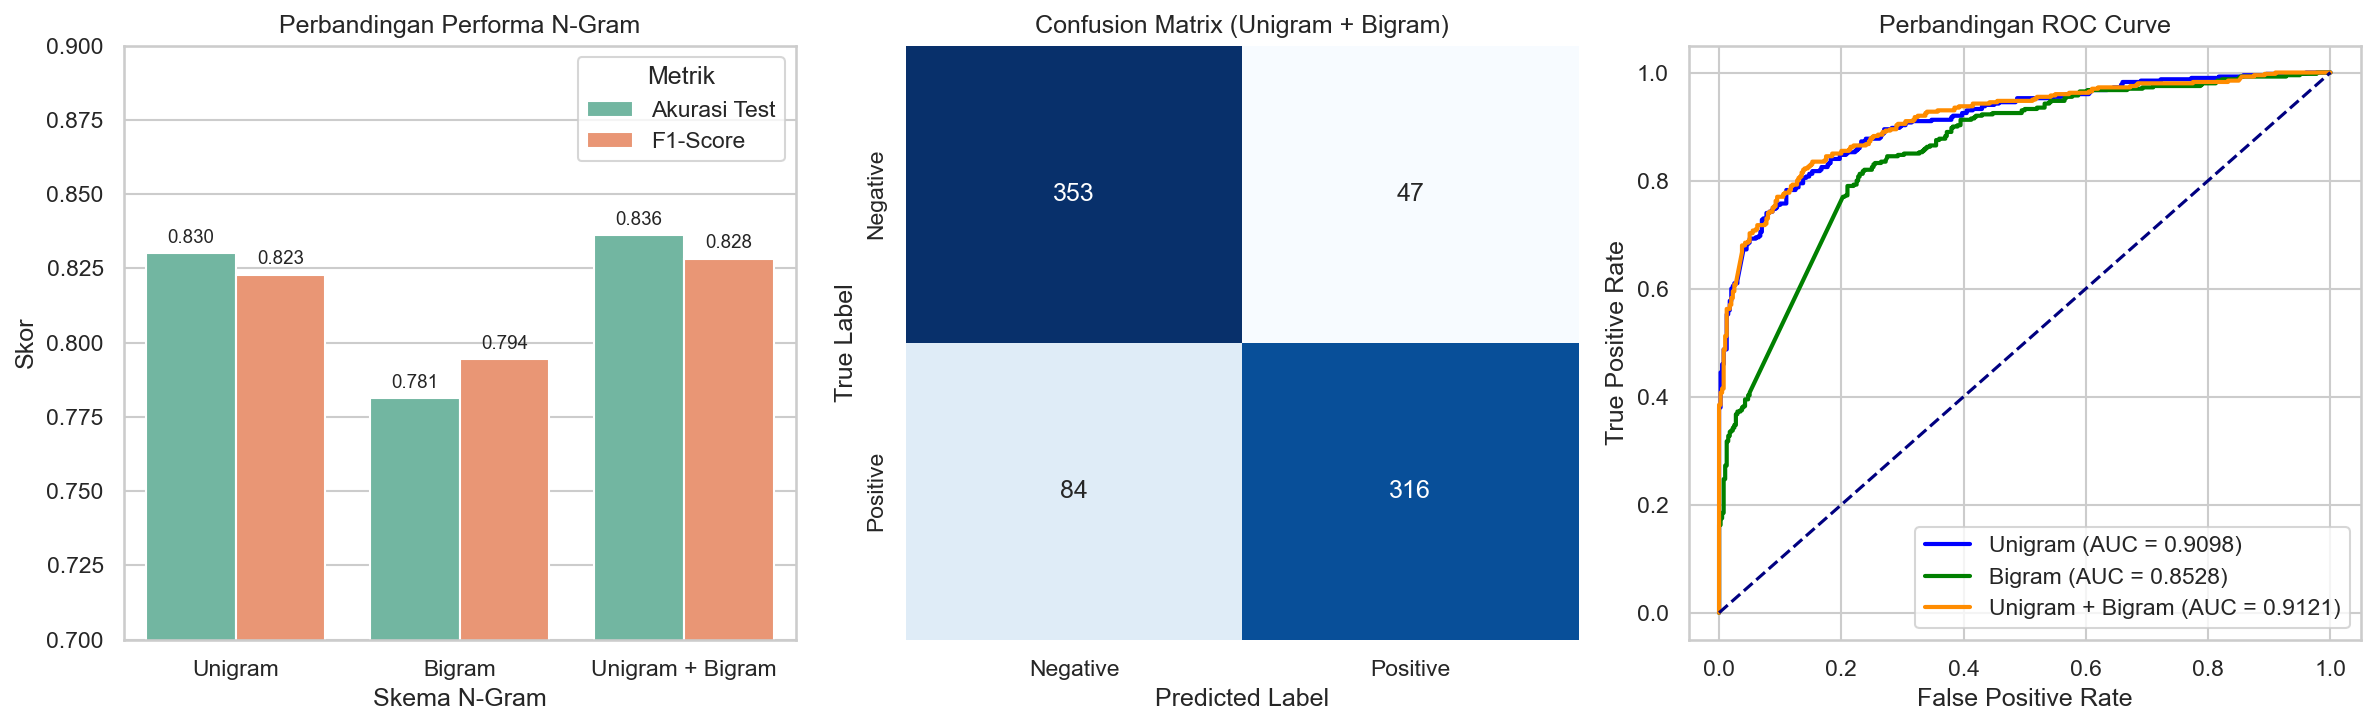

In [21]:
fig = plt.figure(figsize=(16, 5))

ax1 = plt.subplot(1, 3, 1)
df_plot = df_results.melt(id_vars=['Skema N-Gram'], value_vars=['Akurasi Test', 'F1-Score'],
                          var_name='Metrik', value_name='Skor')
sns.barplot(data=df_plot, x='Skema N-Gram', y='Skor', hue='Metrik', palette='Set2', ax=ax1)
ax1.set_title('Perbandingan Performa N-Gram')
ax1.set_ylim(0.7, 0.9)
for p in ax1.patches:
    if p.get_height() > 0:
        ax1.annotate(f'{p.get_height():.3f}', (p.get_x() + p.get_width()/2., p.get_height()),
                     ha='center', va='bottom', fontsize=9, xytext=(0, 3), textcoords='offset points')

ax2 = plt.subplot(1, 3, 2)
cm_name = "Unigram + Bigram"    # dipakai untuk analisis kesalahan, BUKAN karena "terbaik"
cm = confusion_matrix(y_test, models_dict[cm_name]['y_pred'])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax2, cbar=False,
            xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
ax2.set_title(f'Confusion Matrix ({cm_name})')
ax2.set_xlabel('Predicted Label'); ax2.set_ylabel('True Label')

ax3 = plt.subplot(1, 3, 3)
colors = {'Unigram': 'blue', 'Bigram': 'green', 'Unigram + Bigram': 'darkorange'}
for name in models_dict:
    fpr, tpr, _ = roc_curve(y_test, models_dict[name]['y_prob'])
    auc_val = df_results.loc[df_results['Skema N-Gram'] == name, 'ROC-AUC'].values[0]
    ax3.plot(fpr, tpr, label=f'{name} (AUC = {auc_val:.4f})', color=colors[name], lw=2)
ax3.plot([0, 1], [0, 1], color='navy', linestyle='--')
ax3.set_xlabel('False Positive Rate'); ax3.set_ylabel('True Positive Rate')
ax3.set_title('Perbandingan ROC Curve'); ax3.legend(loc='lower right')

plt.tight_layout()
plt.show()

## Gambar 2 dan Gambar 3 untuk artikel
Menyimpan confusion matrix tiga konfigurasi (Gambar 2) dan kurva ROC (Gambar 3) sebagai berkas gambar terpisah.

Unigram            TN=348 FP=52 FN=84 TP=316
Bigram             TN=287 FP=113 FN=62 TP=338
Unigram + Bigram   TN=353 FP=47 FN=84 TP=316


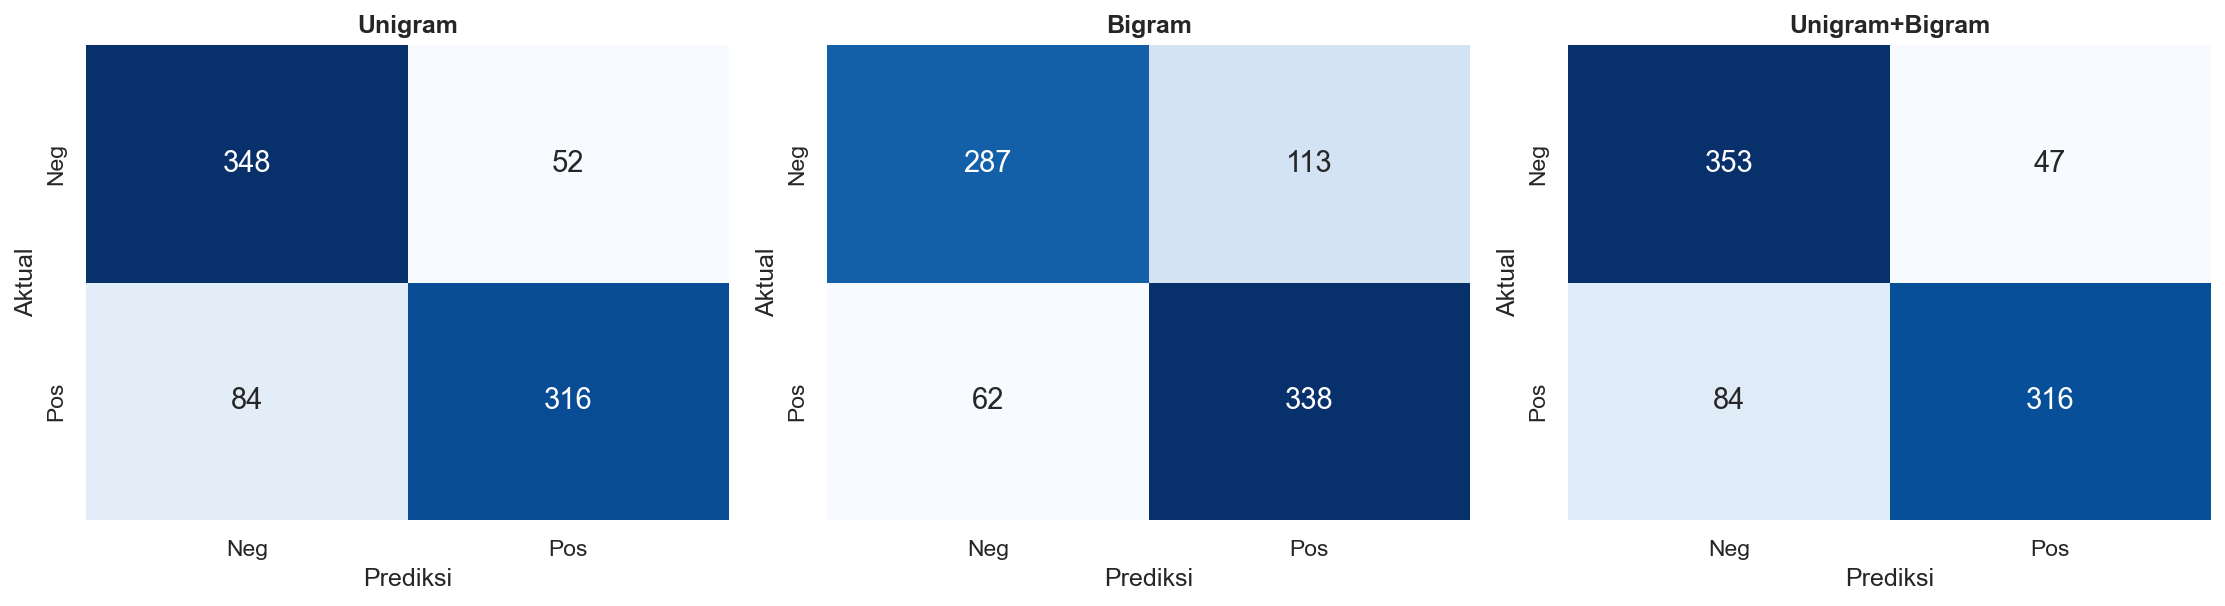

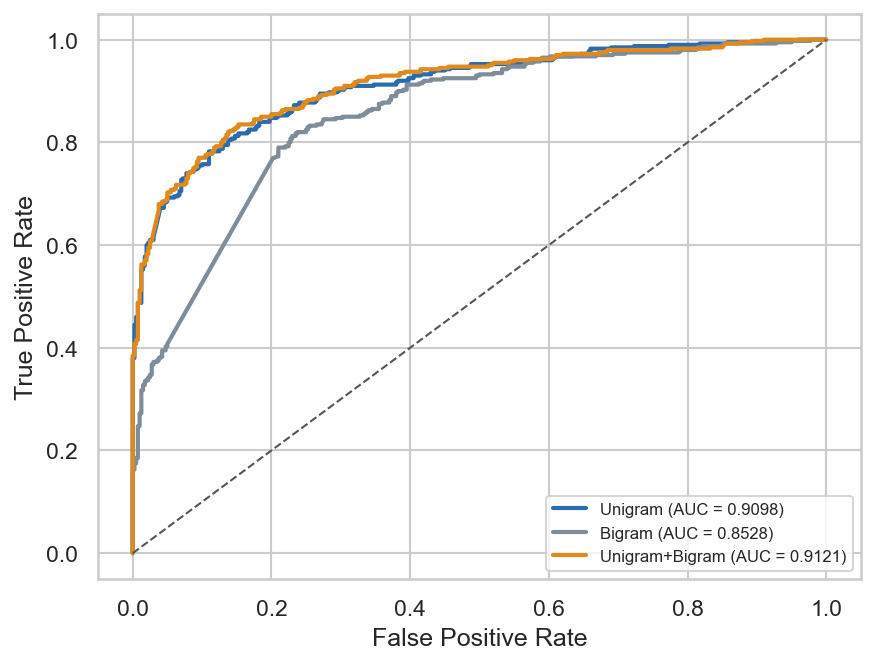

In [22]:
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score

# Gambar 2 — confusion matrix tiga konfigurasi
urutan = ['Unigram', 'Bigram', 'Unigram + Bigram']
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, name in zip(axes, urutan):
    cm = confusion_matrix(y_test, models_dict[name]['y_pred'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                annot_kws={'size': 14}, xticklabels=['Neg', 'Pos'], yticklabels=['Neg', 'Pos'])
    ax.set_title(name.replace(' + ', '+'), fontweight='bold')
    ax.set_xlabel('Prediksi'); ax.set_ylabel('Aktual')
    print(f"{name:18s} TN={cm[0,0]} FP={cm[0,1]} FN={cm[1,0]} TP={cm[1,1]}")
plt.tight_layout()
plt.savefig('fig2_confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

# Gambar 3 — kurva ROC
warna = {'Unigram': '#2B6CB0', 'Bigram': '#7F8C9A', 'Unigram + Bigram': '#E08A1E'}
fig, ax = plt.subplots(figsize=(6, 4.6))
for name in urutan:
    prob = models_dict[name]['y_prob']
    fpr, tpr, _ = roc_curve(y_test, prob)
    ax.plot(fpr, tpr, lw=2, color=warna[name],
            label=f"{name.replace(' + ', '+')} (AUC = {roc_auc_score(y_test, prob):.4f})")
ax.plot([0, 1], [0, 1], '--', color='#555555', lw=1)
ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate')
ax.legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.savefig('fig3_roc.png', dpi=300, bbox_inches='tight')
plt.show()
